Saving DATA original JDRCTR.csv to DATA original JDRCTR (1).csv
Dataset shape: (426, 96)
Shape: (426, 96)

Dtypes summary:
object     86
float64    10
Name: count, dtype: int64

Variables with missing data: 70 of 96 (72.9%)
Overall cell missingness: 0.44%

Top-15 most-missing variables:
Age                     5
SumPC                   5
SumPLReverse            5
NumberTootwo8           5
NumberNatPair3G         5
AllToothPairs3gr        5
NumberOccPairDenture    5
SumPG                   5
SumAAQ                  5
ToothC                  5
Sex                     3
GoETC                   3
AoidEatGroup            3
GoSwellingPus           3
NoExpensive             3
dtype: int64


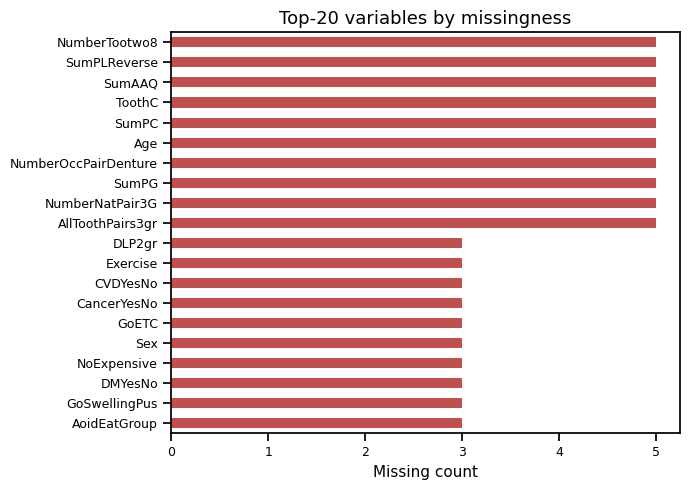

Engineered features created: OralHealthScore, DietaryDiversity, HealthRiskScore, DentalCareScore, AgeGroup


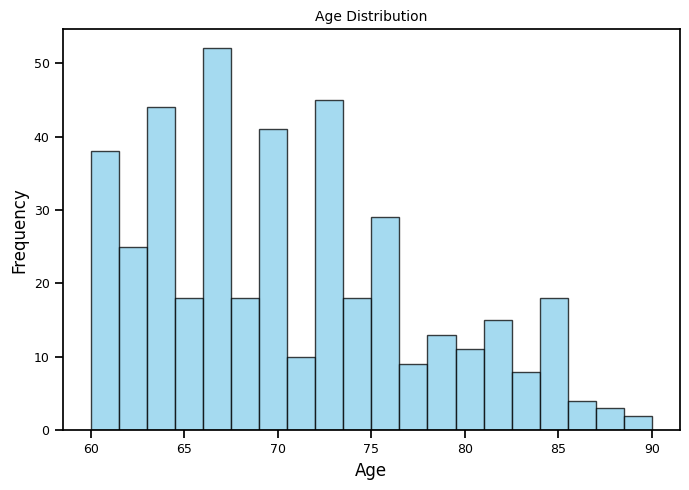

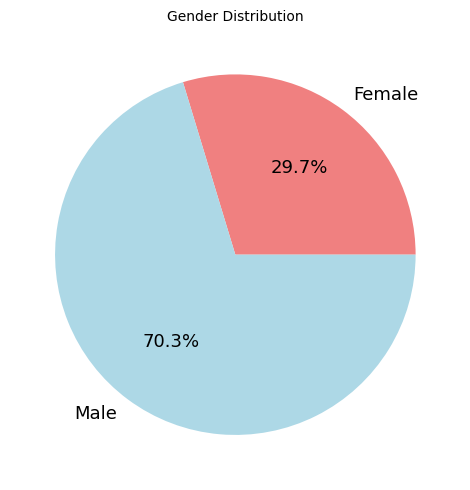

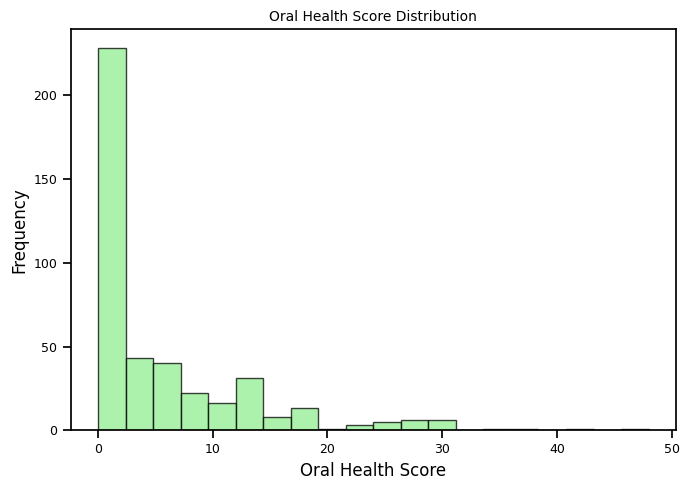

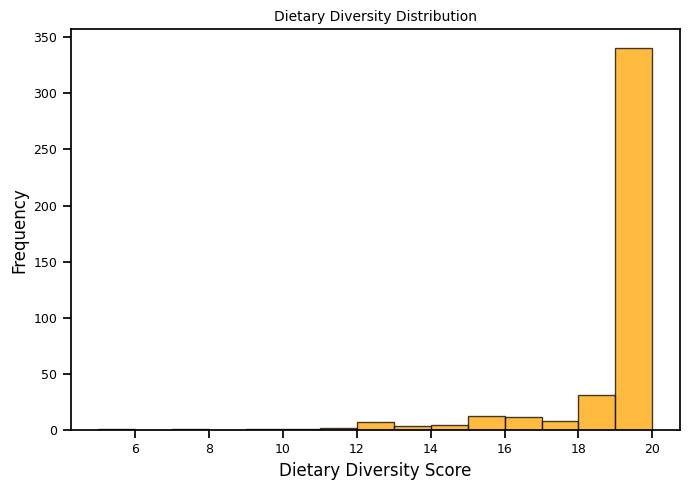

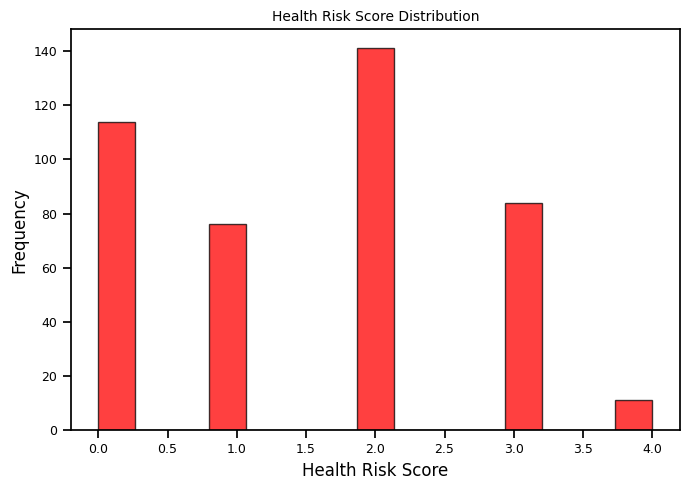

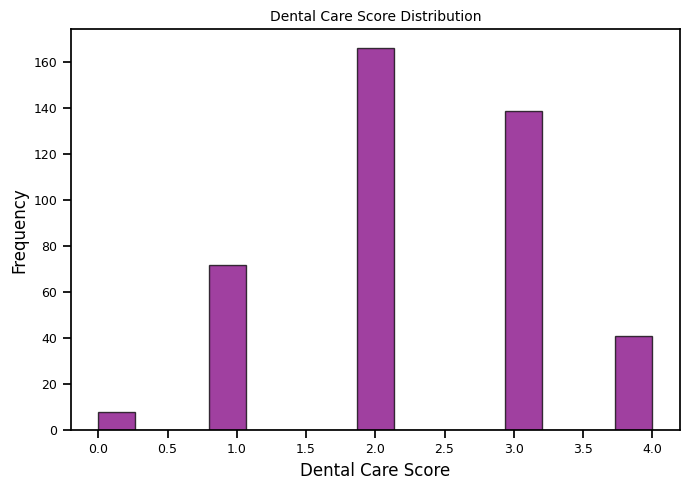

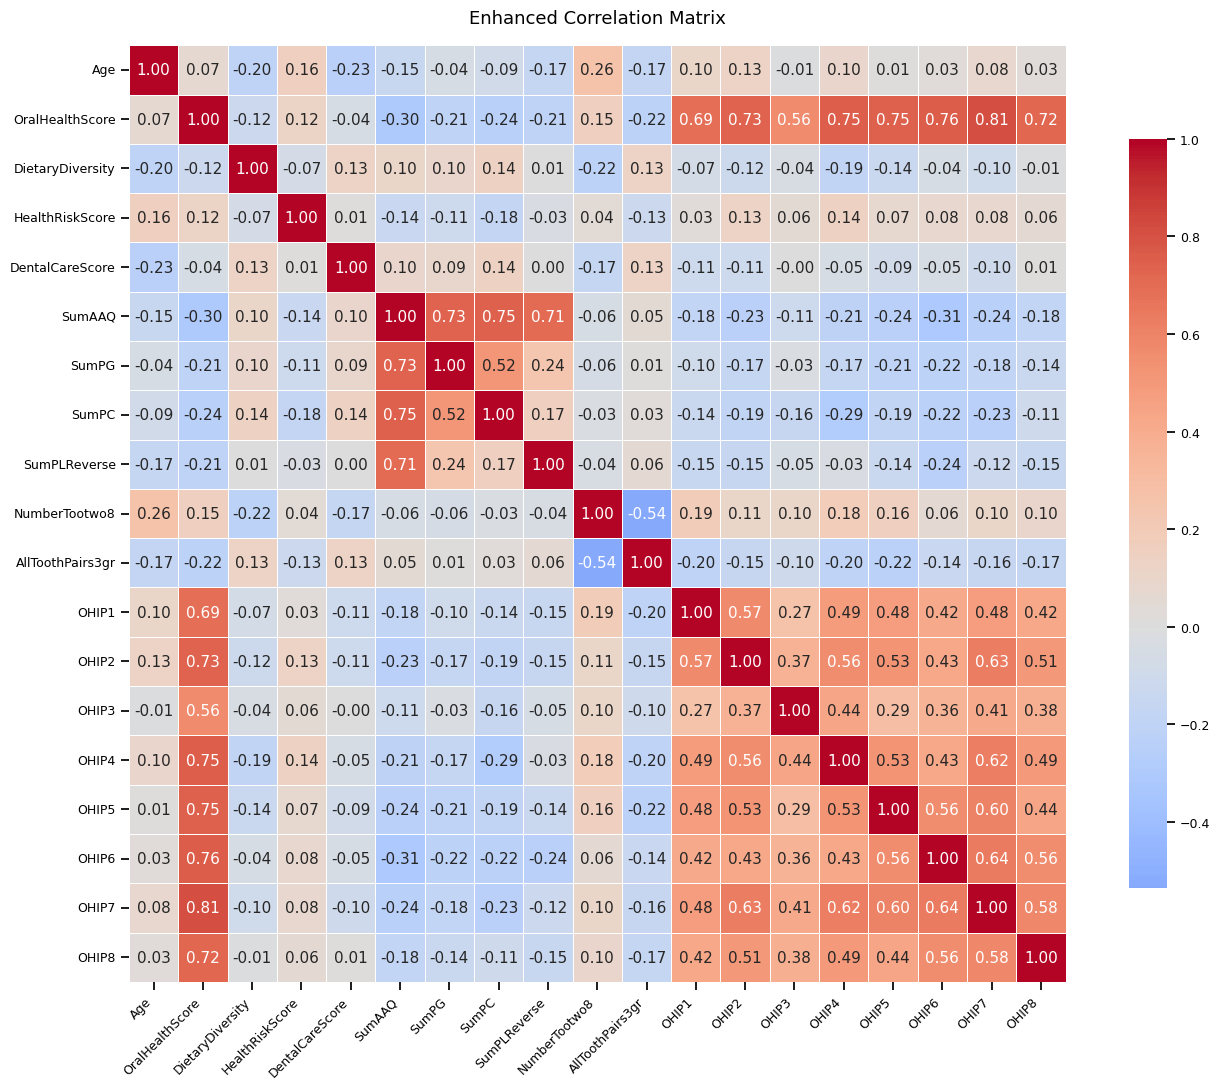

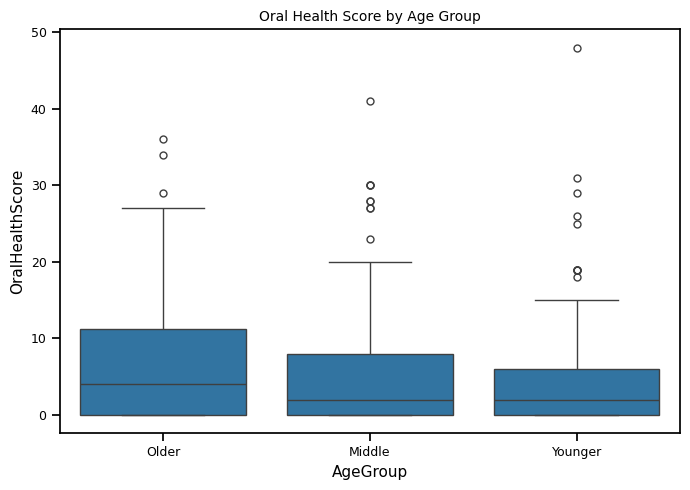

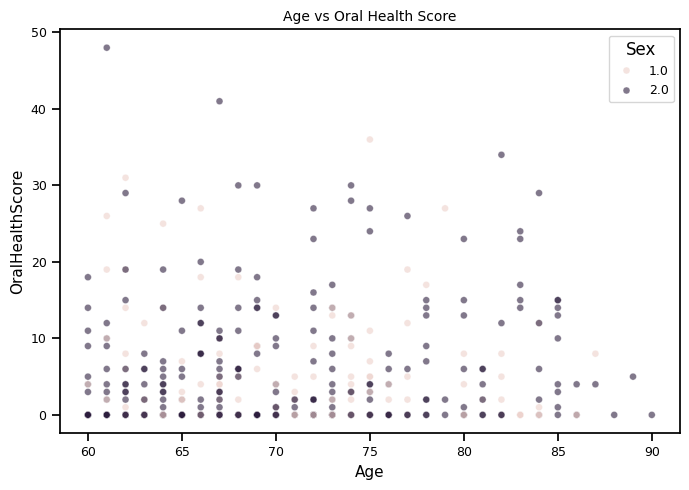

[info] Dropping 5 rows with missing target value.
Target classes and counts:
 AllToothPairs3gr
0    156
1    110
2    155
Name: count, dtype: int64

================ TARGET-LEAKAGE AUDIT ================

Pearson r(NumberNatPair3G, AllToothPairs3gr) = +0.667
Crosstab NumberNatPair3G x AllToothPairs3gr:
AllToothPairs3gr  0.0  1.0  2.0
NumberNatPair3G                
0.0               156   18   54
1.0                 0   92    5
2.0                 0    0   96
Max within-'NumberNatPair3G' target purity (1.0 = deterministic): 0.878 mean / 1.000 max

Pearson r(NumberTootwo8, AllToothPairs3gr) = -0.536
Crosstab NumberTootwo8 x AllToothPairs3gr:
AllToothPairs3gr  0.0  1.0  2.0
NumberTootwo8                  
1.0                 3   43   94
2.0               153   67   61
Max within-'NumberTootwo8' target purity (1.0 = deterministic): 0.608 mean / 0.671 max

Pearson r(NumberOccPairDenture, AllToothPairs3gr) = +0.461
Crosstab NumberOccPairDenture x AllToothPairs3gr:
AllToothPairs3gr      0.0 

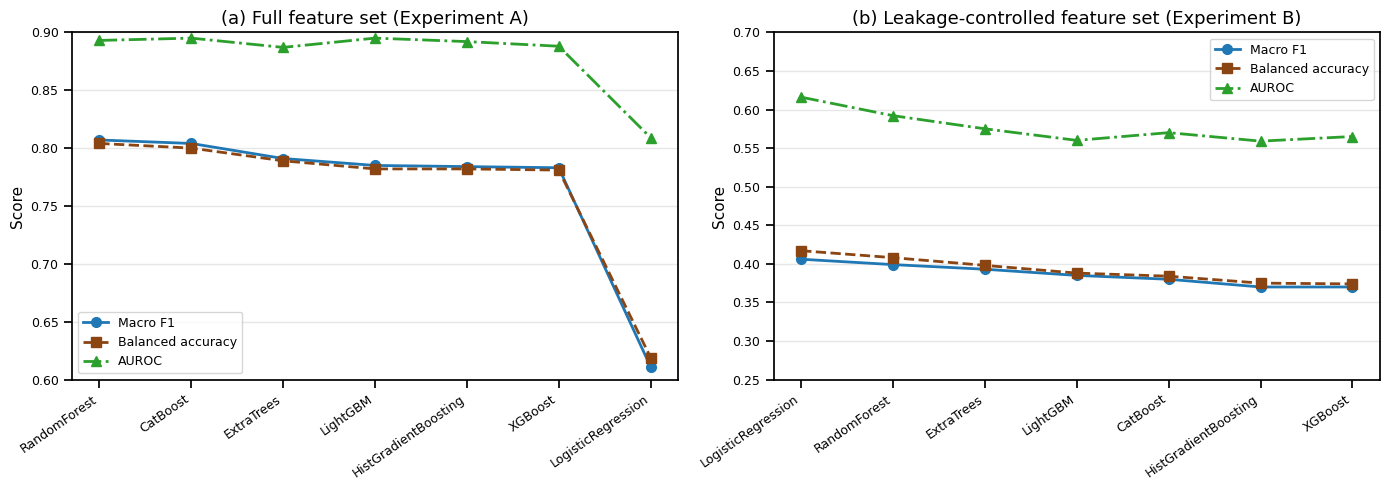

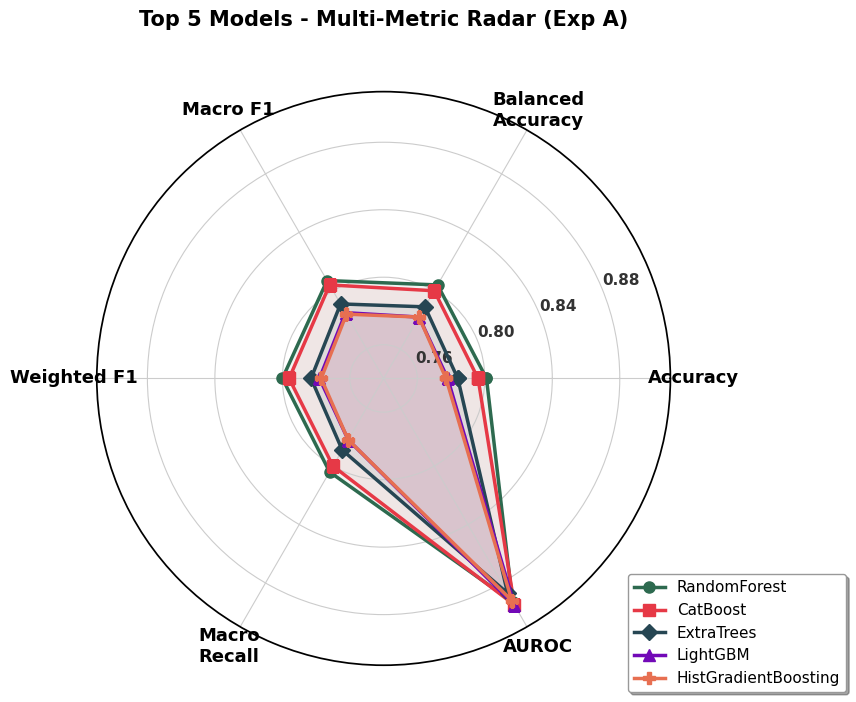

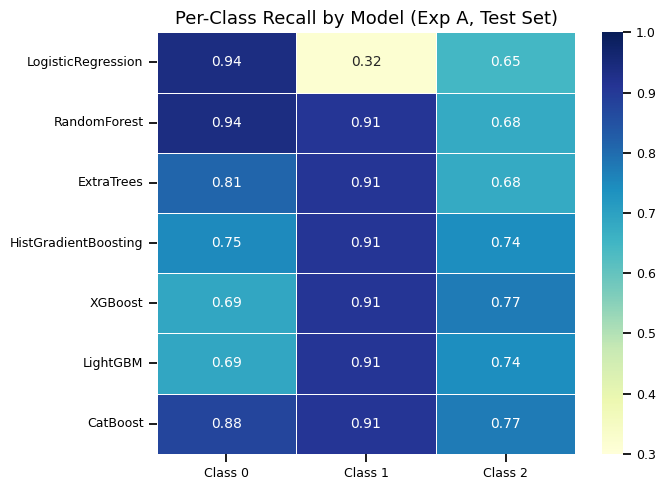

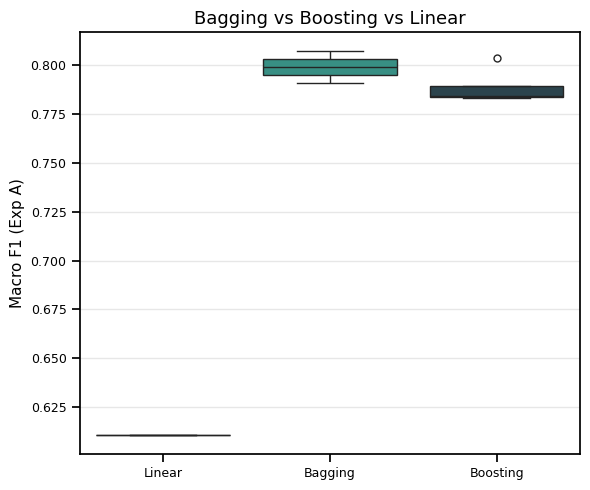

All comparison visualizations saved.
Statistical comparison on: Experiment B (leakage-controlled)
Friedman test across 7 models: chi2=14.229, p=0.02718
Best mean macro-F1: LogisticRegression

Pairwise Wilcoxon vs best (Holm-corrected):
vs_best_LogisticRegression  wilcoxon_p   holm_p
              RandomForest    0.719727 0.719727
                ExtraTrees    0.330261 0.660522
      HistGradientBoosting    0.055359 0.276794
                   XGBoost    0.015076 0.090454
                  LightGBM    0.276855 0.830566
                  CatBoost    0.207764 0.831055
RandomForest           nested macro-F1 = 0.419 ± 0.031
XGBoost                nested macro-F1 = 0.395 ± 0.050
LightGBM               nested macro-F1 = 0.374 ± 0.044
CatBoost               nested macro-F1 = 0.380 ± 0.029
ExtraTrees             nested macro-F1 = 0.410 ± 0.015
HistGradientBoosting   nested macro-F1 = 0.379 ± 0.040

Overall best model (by primary CV macro-F1): LogisticRegression
Best params: {'clf__C': 0.1}
Best

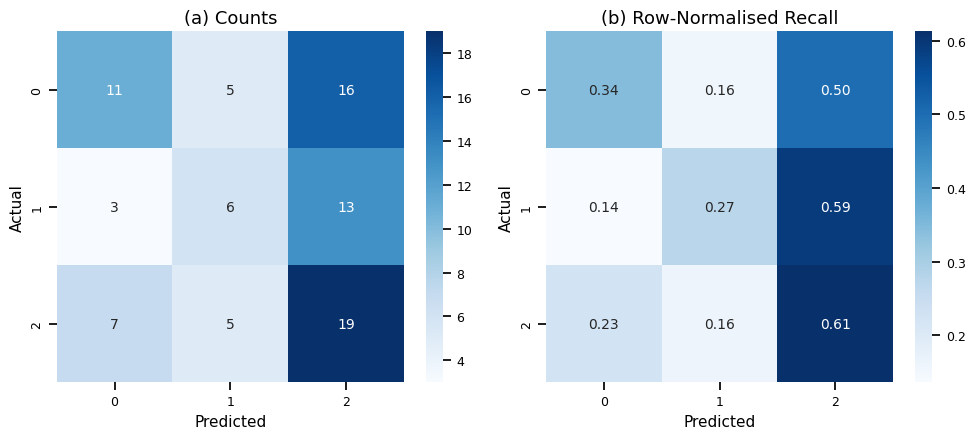

Test macro-F1 = 0.404 (bootstrap 95% CI [0.299, 0.506])
Multiclass Brier score (mean one-vs-rest, lower is better): 0.2199


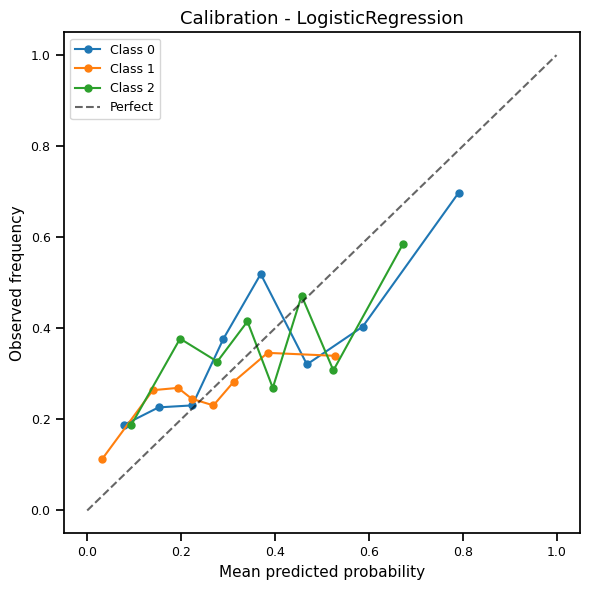

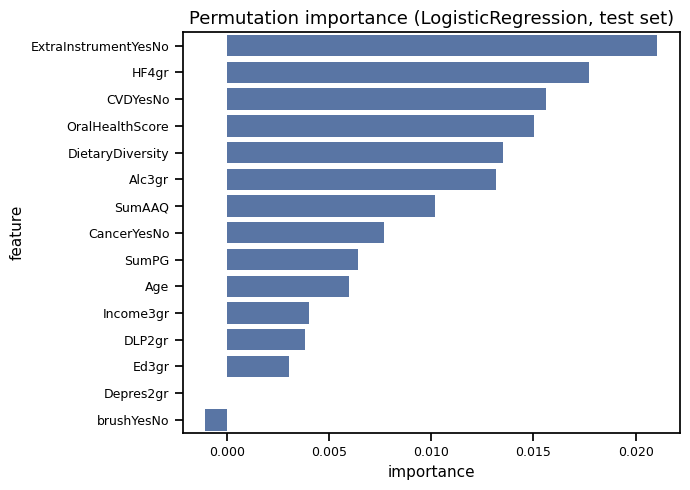

             feature  importance
ExtraInstrumentYesNo    0.021064
               HF4gr    0.017707
            CVDYesNo    0.015603
     OralHealthScore    0.015030
    DietaryDiversity    0.013492
              Alc3gr    0.013191
              SumAAQ    0.010172
         CancerYesNo    0.007701
               SumPG    0.006438
                 Age    0.005975
           Income3gr    0.004003
              DLP2gr    0.003841
               Ed3gr    0.003028
           Depres2gr    0.000000
          brushYesNo   -0.001064


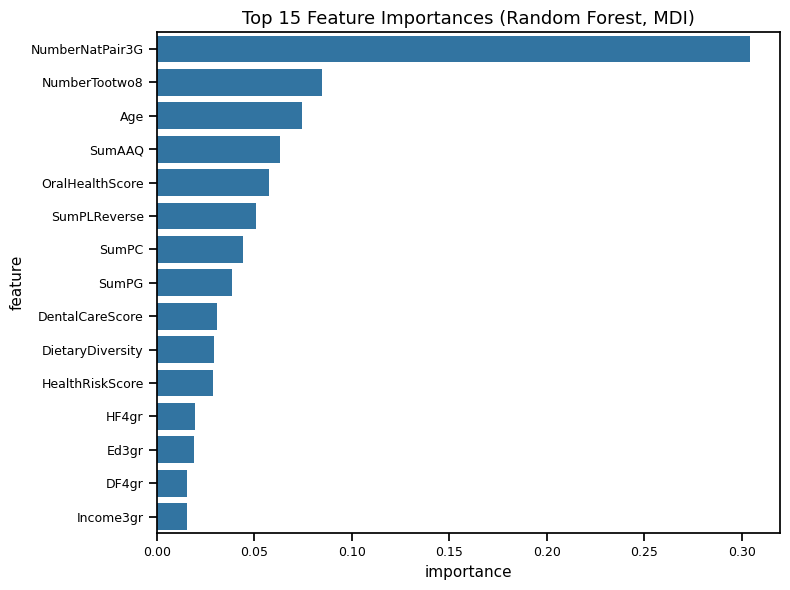

[info] SHAP skipped (library missing or best model not tree-based).
=== Modality ablation (leakage-controlled) ===
          config  n_features    f1_macro  delta_vs_prev
     A1 clinical           9 0.338±0.043            NaN
 A2 +demographic          13 0.374±0.038          0.037
 A3 +behavioural          20 0.377±0.032          0.002
     A4 +dietary          21 0.374±0.034         -0.002
A5 +psychosocial          26 0.408±0.040          0.033

Raw features only     : macro-F1 0.380 ± 0.032  (n=22)
Raw + engineered      : macro-F1 0.399 ± 0.042  (n=26)
Delta from engineering: +0.019 macro-F1


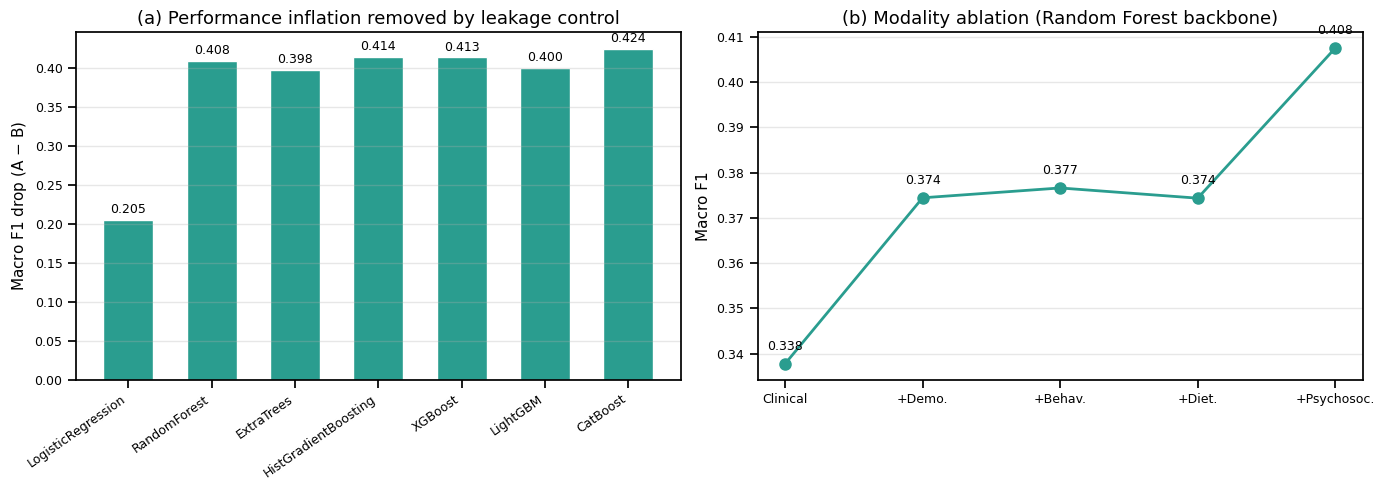

Figure 3 (inflation + ablation) saved.
Median (paper default)   macro-F1 = 0.399 ± 0.042
KNN (k=5)                macro-F1 = 0.399 ± 0.042
Iterative (MICE-like)    macro-F1 = 0.399 ± 0.042
Misclassified: 49 of 85

Feature means, misclassified vs correct:
                  misclassified_mean  correct_mean
Age                            70.63         69.03
SumAAQ                         44.33         45.53
OralHealthScore                 4.86          5.97
HealthRiskScore                 1.31          1.19
DietaryDiversity               19.14         19.00
DentalCareScore                 2.33          2.50

Most frequent confusions (true -> pred):
true  pred
0     2       16
1     2       13
2     0        7
0     1        5
2     1        5
1     0        3
Random Forest        test acc=0.8000  CV=0.7799±0.0584
Logistic Regression  test acc=0.6706  CV=0.6398±0.0315
Legacy tuned RF best params: {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 200}
Legacy tuned RF best CV: 0.8

In [2]:
# ## Cell 1 --- Dependencies (safe installer; works on Colab and locally)



def _ensure(pkg, import_name=None):
    """Install a package only if it is not already importable (Colab-safe)."""
    import importlib, subprocess, sys
    name = import_name or pkg
    try:
        importlib.import_module(name)
        return True
    except Exception:
        try:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
            importlib.import_module(name)
            return True
        except Exception as e:
            print(f"[warn] could not install {pkg}: {e}")
            return False

# Core stack is pre-installed on Colab; the optional learners below are not.
HAS_XGB     = _ensure("xgboost",  "xgboost")
HAS_LGBM    = _ensure("lightgbm", "lightgbm")
HAS_CATBOOST= _ensure("catboost", "catboost")
HAS_SHAP    = _ensure("shap",     "shap")



# ## Cell 2 --- Imports and global configuration



import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, cross_val_score, cross_validate, cross_val_predict,
    GridSearchCV, StratifiedKFold, RepeatedStratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, recall_score,
    roc_auc_score, confusion_matrix, classification_report, brier_score_loss)
from sklearn.calibration import calibration_curve
from scipy import stats as sstats

RANDOM_STATE = 42
N_SPLITS  = 5     # CV folds
N_REPEATS = 3     # repeats for RepeatedStratifiedKFold (raise to 5 for final runs)
np.random.seed(RANDOM_STATE)
sns.set_context("notebook")

# --- Global figure settings (readable, paper-ready) ---
plt.rcParams.update({
    "figure.dpi":     100,
    "savefig.dpi":    200,
    "font.size":       10,
    "axes.titlesize":  13,
    "axes.labelsize":  11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "lines.linewidth": 1.5,
    "lines.markersize": 5,
    "figure.facecolor": "white",
})

CV_REPEATED = RepeatedStratifiedKFold(
    n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)
CV_SIMPLE   = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

SCORING = {
    "accuracy":          "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro":          "f1_macro",
    "f1_weighted":       "f1_weighted",
    "recall_macro":      "recall_macro",
    "roc_auc_ovr":       "roc_auc_ovr",
}



# ## Cell 3 --- Load the dataset
# On Colab this opens the upload dialog; locally, set `FILE_NAME` to your path.



try:
    from google.colab import files
    uploaded = files.upload()
    FILE_NAME = list(uploaded.keys())[0]
except Exception:
    FILE_NAME = "DATA original JDRCTR.csv"   # <-- set local path if not on Colab

df = pd.read_csv(FILE_NAME, encoding="utf-8")
print("Dataset shape:", df.shape)
df.head()



# ## Cell 4 --- Initial exploration and missing-data analysis
# (Same exploration as before, plus an explicit missingness profile.)



print("Shape:", df.shape)
print("\nDtypes summary:")
print(df.dtypes.value_counts())

miss = df.isnull().sum()
miss = miss[miss > 0].sort_values(ascending=False)
print(f"\nVariables with missing data: {len(miss)} of {df.shape[1]} "
      f"({100*len(miss)/df.shape[1]:.1f}%)")
print("Overall cell missingness: "
      f"{100*df.isnull().sum().sum()/df.size:.2f}%")
print("\nTop-15 most-missing variables:")
print(miss.head(15))

# Missingness bar (top 20) - documents the imputation burden
if len(miss) > 0:
    plt.figure(figsize=(7, 5))
    miss.head(20).sort_values().plot(kind="barh", color="#c0504d")
    plt.xlabel("Missing count"); plt.title("Top-20 variables by missingness")
    plt.tight_layout(); plt.savefig("figA_missingness.png", dpi=150); plt.show()



# ## Cell 5 --- Type coercion and engineered features
# The five engineered composites are **row-wise** transforms of raw columns,
# so computing them here introduces **no leakage** (they use no cross-row
# statistics). Median/mode imputation, which *does* use cross-row statistics,
# is deferred to the CV pipelines in later cells.



# Coerce object columns to numeric (invalid strings -> NaN), matching the paper.
for col in df.columns:
    if df[col].dtype == "object":
        df[col] = pd.to_numeric(df[col], errors="coerce")

# --- Engineered features (unchanged definitions from the original study) ---
def create_age_groups(age):
    if pd.isna(age):
        return np.nan
    if age < 65:  return "Younger"
    if age < 75:  return "Middle"
    return "Older"

df["AgeGroup"] = df["Age"].apply(create_age_groups)

ohip_columns = [f"OHIP{i}" for i in range(1, 15)]
df["OralHealthScore"] = df[ohip_columns].sum(axis=1, skipna=True)

food_columns = ['BoiledRice', 'JasmineRice', 'StickyRice', 'Noodles',
                'MincedPork', 'BoiledEgg', 'FriedEgg', 'FriedChicken',
                'CrispyPork', 'DriedShrimp', 'BoiledCauliflower',
                'StirfriedChineseKale', 'StirfriedWaterSpinach',
                'StirfriedWaterMimosa', 'Orange', 'Banana', 'Guava',
                'SteamedCakes', 'Galangal', 'FoodInGrainLikeForm']
df["DietaryDiversity"] = df[food_columns].apply(lambda x: (x != 3).sum(), axis=1)

health_risk_columns = ['DMYesNo', 'HTYesNo', 'CVDYesNo', 'CancerYesNo', 'DLP2gr', 'Depres2gr']
df["HealthRiskScore"] = df[health_risk_columns].sum(axis=1, skipna=True)

dental_care_columns = ['brushYesNo', 'ExtraInstrumentYesNo', 'DentVisit2gr', 'Exercise']
df["DentalCareScore"] = df[dental_care_columns].sum(axis=1, skipna=True)

print("Engineered features created: OralHealthScore, DietaryDiversity, "
      "HealthRiskScore, DentalCareScore, AgeGroup")



# ## Cell 6 --- Exploratory figures (kept from the original study)
# These reproduce the paper's Figures 3-6 and 9 inputs at publication DPI.



_DPI = 300
def _hist(col, color, title, xlabel, fname, bins=20):
    plt.figure(figsize=(7, 5))
    plt.hist(df[col].dropna(), bins=bins, alpha=0.75, color=color, edgecolor="black")
    plt.title(title, fontsize=10); plt.xlabel(xlabel, fontsize=12); plt.ylabel("Frequency", fontsize=12)
    plt.tight_layout(); plt.savefig(fname, dpi=_DPI, bbox_inches="tight"); plt.show()

_hist("Age", "skyblue", "Age Distribution", "Age", "fig3a_age_distribution.png")
plt.figure(figsize=(6, 5))
gc = df["Sex"].value_counts().sort_index()
plt.pie(gc.values, labels=["Female", "Male"], autopct="%1.1f%%",
        colors=["lightcoral", "lightblue"], textprops={"fontsize": 13})
plt.title("Gender Distribution", fontsize=10); plt.tight_layout()
plt.savefig("fig3b_gender_distribution.png", dpi=_DPI, bbox_inches="tight"); plt.show()

_hist("OralHealthScore", "lightgreen", "Oral Health Score Distribution", "Oral Health Score", "fig3c_oralhealthscore_distribution.png")
_hist("DietaryDiversity", "orange", "Dietary Diversity Distribution", "Dietary Diversity Score", "fig4a_dietary_distribution.png", bins=15)
_hist("HealthRiskScore", "red", "Health Risk Score Distribution", "Health Risk Score", "fig4b_healthrisk_distribution.png", bins=15)
_hist("DentalCareScore", "purple", "Dental Care Score Distribution", "Dental Care Score", "fig4c_dentalcare_distribution.png", bins=15)

# Correlation heatmap (Figure 6)
plt.figure(figsize=(14, 11))
corr_cols = ['Age', 'OralHealthScore', 'DietaryDiversity', 'HealthRiskScore',
             'DentalCareScore', 'SumAAQ', 'SumPG', 'SumPC', 'SumPLReverse',
             'NumberTootwo8', 'AllToothPairs3gr'] + ohip_columns[:8]
sns.heatmap(df[corr_cols].corr(), annot=True, cmap="coolwarm", center=0,
            fmt=".2f", annot_kws={"size": 11}, square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.8})
plt.title("Enhanced Correlation Matrix", fontsize=13, pad=16)
plt.xticks(rotation=45, ha="right"); plt.yticks(rotation=0)
plt.tight_layout(); plt.savefig("fig6_correlation_heatmap.png", dpi=_DPI, bbox_inches="tight"); plt.show()

# Age-stratified oral health (Figure 5a/5b)
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="AgeGroup", y="OralHealthScore",
            order=["Older", "Middle", "Younger"])
plt.title("Oral Health Score by Age Group", fontsize=10); plt.tight_layout()
plt.savefig("fig5a_ohs_by_agegroup.png", dpi=_DPI, bbox_inches="tight"); plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Age", y="OralHealthScore", hue="Sex", alpha=0.6)
plt.title("Age vs Oral Health Score", fontsize=10); plt.legend(title="Sex")
plt.tight_layout(); plt.savefig("fig5b_age_vs_ohs_by_sex.png", dpi=_DPI, bbox_inches="tight"); plt.show()



# ## Cell 7 --- Feature sets, target, and the TARGET-LEAKAGE AUDIT
# **This is the most important integrity check.** The target `AllToothPairs3gr`
# and the clinical count `NumberNatPair3G` may both derive from the same
# underlying occluding-pair measurement. We quantify their relationship and
# define a leakage-controlled feature set (Experiment B) that removes the
# direct tooth-pair-count variables.



TARGET = "AllToothPairs3gr"

demographic  = ['Age', 'Sex', 'Ed3gr', 'Income3gr']
clinical     = ['HF4gr', 'DF4gr', 'NumberNatPair3G', 'NumberTootwo8']
comorbid     = ['DMYesNo', 'HTYesNo', 'CVDYesNo', 'CancerYesNo', 'DLP2gr', 'Depres2gr']
behavioural  = ['Smoking3gr', 'Alc3gr', 'Exercise', 'brushYesNo',
                'ExtraInstrumentYesNo', 'DentVisit2gr']
psychosocial = ['SumAAQ', 'SumPG', 'SumPC', 'SumPLReverse']
engineered   = ['OralHealthScore', 'DietaryDiversity', 'HealthRiskScore', 'DentalCareScore']

FULL_FEATURES = demographic + clinical + comorbid + behavioural + psychosocial + engineered
# Direct occluding-pair counts that plausibly co-derive with the target:
LEAKAGE_COLS = ['NumberNatPair3G', 'NumberTootwo8']
LEAKY_FEATURES = FULL_FEATURES                                   # Experiment A
CLEAN_FEATURES = [f for f in FULL_FEATURES if f not in LEAKAGE_COLS]  # Experiment B

# Continuous vs categorical-coded (for correct imputation strategy)
CONTINUOUS = ['Age', 'OralHealthScore', 'DietaryDiversity', 'HealthRiskScore',
              'DentalCareScore', 'SumAAQ', 'SumPG', 'SumPC', 'SumPLReverse',
              'NumberNatPair3G', 'NumberTootwo8']

# Drop rows where the target itself is missing (can't train on them)
_mask = df[TARGET].notna()
if (~_mask).any():
    print(f"[info] Dropping {(~_mask).sum()} rows with missing target value.")
    df = df.loc[_mask].reset_index(drop=True)

y = df[TARGET].astype(float).round().astype(int)
print("Target classes and counts:\n", y.value_counts().sort_index())

print("\n================ TARGET-LEAKAGE AUDIT ================")
for c in LEAKAGE_COLS + ['NumberOccPairDenture', 'ToothC']:
    if c in df.columns:
        try:
            r = df[[c, TARGET]].corr().iloc[0, 1]
        except Exception:
            r = np.nan
        print(f"\nPearson r({c}, {TARGET}) = {r:+.3f}")
        ct = pd.crosstab(df[c], df[TARGET])
        print(f"Crosstab {c} x {TARGET}:\n{ct}")
        # Is the target an (almost) deterministic function of this variable?
        grp = df.groupby(c)[TARGET].agg(lambda s: s.value_counts(normalize=True).max())
        print(f"Max within-'{c}' target purity (1.0 = deterministic): "
              f"{grp.mean():.3f} mean / {grp.max():.3f} max")

# Mutual information of each leakage-candidate with the target
from sklearn.feature_selection import mutual_info_classif
_present = [c for c in LEAKAGE_COLS if c in df.columns]
if _present:
    _tmp = df[_present].apply(lambda s: s.fillna(s.median()))
    mi = mutual_info_classif(_tmp, y, discrete_features=True, random_state=RANDOM_STATE)
    print("\nMutual information with target:")
    for name, val in zip(_present, mi):
        print(f"  MI({name}) = {val:.3f}")
print("\nInterpretation: very high correlation / near-1.0 purity / high MI means the"
      "\nvariable largely restates the target and MUST be reported as a leakage risk."
      "\nExperiment B below removes these variables and re-runs the whole benchmark.")



# ## Cell 8 --- Leak-free preprocessing + model zoo
# Imputation and scaling live **inside** each model pipeline, so they are fit
# on the training fold only. Tree/boosting models run unscaled; LR receives
# standardised input.



def build_preprocessor(feature_list, scale):
    cont = [c for c in CONTINUOUS if c in feature_list]
    cat  = [c for c in feature_list if c not in cont]
    ct = ColumnTransformer(
        [("num", SimpleImputer(strategy="median"), cont),
         ("cat", SimpleImputer(strategy="most_frequent"), cat)],
        remainder="drop")
    steps = [("prep", ct)]
    if scale:
        steps.append(("scale", StandardScaler()))
    return Pipeline(steps), cont + cat   # return ordered feature names too


def make_model_zoo(n_classes=3):
    """Return {name: dict(estimator, scale, grid)} with optional libs guarded."""
    zoo = {}
    zoo["LogisticRegression"] = dict(
        estimator=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        scale=True,
        grid={"clf__C": [0.1, 1.0, 10.0]})
    zoo["RandomForest"] = dict(
        estimator=RandomForestClassifier(random_state=RANDOM_STATE),
        scale=False,
        grid={"clf__n_estimators": [200, 400], "clf__max_depth": [None, 10],
              "clf__min_samples_split": [2, 5]})
    zoo["ExtraTrees"] = dict(
        estimator=ExtraTreesClassifier(random_state=RANDOM_STATE),
        scale=False,
        grid={"clf__n_estimators": [300, 500], "clf__max_depth": [None, 12]})
    zoo["HistGradientBoosting"] = dict(
        estimator=HistGradientBoostingClassifier(random_state=RANDOM_STATE),
        scale=False,
        grid={"clf__learning_rate": [0.05, 0.1], "clf__max_depth": [None, 3]})
    if HAS_XGB:
        from xgboost import XGBClassifier
        zoo["XGBoost"] = dict(
            estimator=XGBClassifier(
                objective="multi:softprob", num_class=n_classes,
                eval_metric="mlogloss", tree_method="hist",
                random_state=RANDOM_STATE, n_jobs=-1),
            scale=False,
            grid={"clf__n_estimators": [300], "clf__max_depth": [3, 5],
                  "clf__learning_rate": [0.05, 0.1], "clf__subsample": [0.8],
                  "clf__colsample_bytree": [0.8], "clf__reg_lambda": [1.0]})
    if HAS_LGBM:
        from lightgbm import LGBMClassifier
        zoo["LightGBM"] = dict(
            estimator=LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
            scale=False,
            grid={"clf__n_estimators": [300], "clf__num_leaves": [15, 31],
                  "clf__learning_rate": [0.05], "clf__reg_lambda": [1.0]})
    if HAS_CATBOOST:
        from catboost import CatBoostClassifier
        zoo["CatBoost"] = dict(
            estimator=CatBoostClassifier(verbose=0, random_state=RANDOM_STATE),
            scale=False,
            grid={"clf__iterations": [300], "clf__depth": [4, 6],
                  "clf__learning_rate": [0.05]})
    print("Models in zoo:", list(zoo.keys()))
    return zoo


def make_pipeline_for(model_spec, feature_list):
    prep, names = build_preprocessor(feature_list, model_spec["scale"])
    pipe = Pipeline(list(prep.steps) + [("clf", model_spec["estimator"])])
    return pipe, names



# ## Cell 9 --- Evaluation utilities (repeated CV, CIs, nested CV, stats)



def ci95(vals):
    vals = np.asarray(vals, dtype=float)
    m, s, n = vals.mean(), vals.std(ddof=1), len(vals)
    half = 1.96 * s / np.sqrt(n)          # normal approx (folds not fully independent)
    return m, s, (m - half, m + half)

def repeated_cv_table(zoo, X, y, cv=CV_REPEATED):
    """Repeated stratified CV for every model; returns a tidy DataFrame + raw folds."""
    rows, fold_f1 = [], {}
    for name, spec in zoo.items():
        pipe, _ = make_pipeline_for(spec, X.columns.tolist())
        try:
            res = cross_validate(pipe, X, y, scoring=SCORING, cv=cv,
                                 n_jobs=-1, error_score="raise")
        except Exception as e:
            print(f"[warn] {name} failed in CV: {e}")
            continue
        fold_f1[name] = res["test_f1_macro"]
        row = {"model": name}
        for key in SCORING:
            m, s, (lo, hi) = ci95(res[f"test_{key}"])
            row[key] = f"{m:.3f}±{s:.3f}"
            if key == "f1_macro":
                row["f1_macro_CI95"] = f"[{lo:.3f}, {hi:.3f}]"
                row["_f1_sort"] = m
        rows.append(row)
    tab = pd.DataFrame(rows).sort_values("_f1_sort", ascending=False)
    return tab.drop(columns="_f1_sort"), fold_f1

def nested_cv_f1(spec, X, y, outer=CV_SIMPLE, inner_splits=3):
    """Unbiased macro-F1 via nested CV (inner GridSearch)."""
    if not spec["grid"]:
        pipe, _ = make_pipeline_for(spec, X.columns.tolist())
        return cross_val_score(pipe, X, y, scoring="f1_macro", cv=outer, n_jobs=-1)
    pipe, _ = make_pipeline_for(spec, X.columns.tolist())
    inner = StratifiedKFold(n_splits=inner_splits, shuffle=True, random_state=RANDOM_STATE)
    gs = GridSearchCV(pipe, spec["grid"], scoring="f1_macro", cv=inner, n_jobs=-1)
    return cross_val_score(gs, X, y, scoring="f1_macro", cv=outer, n_jobs=-1)

def friedman_and_pairwise(fold_f1):
    """Friedman across models + pairwise Wilcoxon vs. best (Holm-corrected)."""
    names = list(fold_f1.keys())
    L = min(len(v) for v in fold_f1.values())
    M = np.column_stack([fold_f1[n][:L] for n in names])
    try:
        chi, p = sstats.friedmanchisquare(*[M[:, i] for i in range(M.shape[1])])
        print(f"Friedman test across {len(names)} models: chi2={chi:.3f}, p={p:.4g}")
    except Exception as e:
        print(f"[warn] Friedman failed: {e}")
    best = names[int(np.argmax(M.mean(axis=0)))]
    print(f"Best mean macro-F1: {best}")
    pvals, comps = [], []
    for n in names:
        if n == best:
            continue
        try:
            _, p = sstats.wilcoxon(fold_f1[best][:L], fold_f1[n][:L])
        except Exception:
            p = np.nan
        comps.append(n); pvals.append(p)
    order = np.argsort(pvals); m = len(pvals); holm = [np.nan]*m
    for rank, idx in enumerate(order):
        holm[idx] = min(1.0, pvals[idx]*(m-rank))
    return pd.DataFrame({"vs_best_"+best: comps, "wilcoxon_p": pvals, "holm_p": holm})



# ## Cell 10 --- EXPERIMENT A (full features) : repeated-CV benchmark



zoo = make_model_zoo(n_classes=y.nunique())
X_A = df[LEAKY_FEATURES].copy()
print(f"Experiment A design matrix: {X_A.shape}")

tableA, foldsA = repeated_cv_table(zoo, X_A, y)
print("\n=== Experiment A (full features) - repeated stratified CV ===")
print(tableA.to_string(index=False))
tableA.to_csv("resultsA_full_features.csv", index=False)



# ## Cell 11 --- EXPERIMENT B (leakage-controlled) + A-vs-B delta



X_B = df[CLEAN_FEATURES].copy()
print(f"Experiment B design matrix: {X_B.shape} "
      f"(removed {LEAKAGE_COLS})")

tableB, foldsB = repeated_cv_table(zoo, X_B, y)
print("\n=== Experiment B (leakage-controlled) - repeated stratified CV ===")
print(tableB.to_string(index=False))
tableB.to_csv("resultsB_leakage_controlled.csv", index=False)

# A vs B delta on macro-F1
def _f1mean(folds): return {k: np.mean(v) for k, v in folds.items()}
mA, mB = _f1mean(foldsA), _f1mean(foldsB)
delta = pd.DataFrame({
    "model": list(mA.keys()),
    "f1_macro_A_full":  [mA[k] for k in mA],
    "f1_macro_B_clean": [mB.get(k, np.nan) for k in mA],
})
delta["delta_A_minus_B"] = delta["f1_macro_A_full"] - delta["f1_macro_B_clean"]
print("\n=== A vs B (how much performance depended on tooth-pair-count features) ===")
print(delta.to_string(index=False))
delta.to_csv("results_delta_A_vs_B.csv", index=False)



# ## Cell 12 --- Algorithm comparison visualizations
# Line/marker plots matching paper Figures 2-3, plus radar, heatmap, and
# family boxplot.



def _val(s):
    try: return float(str(s).split("±")[0])
    except: return np.nan

# ===================== FIGURE 2: Model comparison (two-panel line/marker) =====================
a_names = tableA["model"].tolist()
a_f1    = [_val(v) for v in tableA["f1_macro"]]
a_bacc  = [_val(v) for v in tableA["balanced_accuracy"]]
a_auroc = [_val(v) for v in tableA["roc_auc_ovr"]]

b_names = tableB["model"].tolist()
b_f1    = [_val(v) for v in tableB["f1_macro"]]
b_bacc  = [_val(v) for v in tableB["balanced_accuracy"]]
b_auroc = [_val(v) for v in tableB["roc_auc_ovr"]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

ax1.plot(a_names, a_f1,    "o-",  color="#1f77b4", linewidth=2, markersize=7, label="Macro F1")
ax1.plot(a_names, a_bacc,  "s--", color="#8b4513", linewidth=2, markersize=7, label="Balanced accuracy")
ax1.plot(a_names, a_auroc, "^-.", color="#2ca02c", linewidth=2, markersize=7, label="AUROC")
ax1.set_ylabel("Score")
ax1.set_title("(a) Full feature set (Experiment A)")
ax1.set_ylim(0.60, 0.90)
ax1.legend(fontsize=9)
ax1.grid(axis="y", alpha=0.3)
ax1.set_xticklabels(a_names, rotation=35, ha="right", fontsize=9)

ax2.plot(b_names, b_f1,    "o-",  color="#1f77b4", linewidth=2, markersize=7, label="Macro F1")
ax2.plot(b_names, b_bacc,  "s--", color="#8b4513", linewidth=2, markersize=7, label="Balanced accuracy")
ax2.plot(b_names, b_auroc, "^-.", color="#2ca02c", linewidth=2, markersize=7, label="AUROC")
ax2.set_ylabel("Score")
ax2.set_title("(b) Leakage-controlled feature set (Experiment B)")
ax2.set_ylim(0.25, 0.70)
ax2.legend(fontsize=9)
ax2.grid(axis="y", alpha=0.3)
ax2.set_xticklabels(b_names, rotation=35, ha="right", fontsize=9)

plt.tight_layout()
plt.savefig("fig2_model_comparison.pdf", dpi=300, bbox_inches="tight")
plt.savefig("fig2_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# ===================== (d) Radar / spider chart (Exp A, top 5 models) =====================
radar_metrics = ["accuracy", "balanced_accuracy", "f1_macro", "f1_weighted", "recall_macro", "roc_auc_ovr"]
radar_labels  = ["Accuracy", "Balanced\nAccuracy", "Macro F1", "Weighted F1", "Macro\nRecall", "AUROC"]
top5 = tableA.head(5)
fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
angles = np.linspace(0, 2*np.pi, len(radar_metrics), endpoint=False).tolist()
angles += angles[:1]
radar_colors  = ["#2d6a4f", "#e63946", "#264653", "#7209b7", "#e76f51"]
radar_markers = ["o",       "s",       "D",       "^",       "P"]
for idx, (_, row) in enumerate(top5.iterrows()):
    vals = [_val(row[m]) for m in radar_metrics] + [_val(row[radar_metrics[0]])]
    ax.plot(angles, vals, marker=radar_markers[idx], linewidth=2.5, markersize=8,
            label=row["model"], color=radar_colors[idx])
    ax.fill(angles, vals, alpha=0.07, color=radar_colors[idx])
ax.set_thetagrids([a*180/np.pi for a in angles[:-1]], radar_labels, fontsize=13, fontweight="bold")
ax.set_ylim(0.74, 0.91)
ax.set_rticks([0.76, 0.80, 0.84, 0.88])
ax.set_yticklabels(["0.76", "0.80", "0.84", "0.88"], fontsize=11, fontweight="bold", color="#333333")
ax.tick_params(axis="y", pad=8)
ax.set_title("Top 5 Models - Multi-Metric Radar (Exp A)", y=1.10, fontsize=15, fontweight="bold")
ax.legend(loc="lower right", bbox_to_anchor=(1.32, -0.06), fontsize=11,
          frameon=True, fancybox=True, shadow=True, edgecolor="#999999")
ax.grid(color="#cccccc", linewidth=0.8)
plt.tight_layout(); plt.savefig("fig_radar_top5.png", dpi=200, bbox_inches="tight"); plt.show()

# ===================== (e) Per-class recall heatmap (Exp A, held-out) =====================
_Xtr_A, _Xte_A, _ytr_A, _yte_A = train_test_split(
    X_A, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
recall_rows = {}
for name, spec in zoo.items():
    try:
        pipe, _ = make_pipeline_for(spec, LEAKY_FEATURES)
        pipe.fit(_Xtr_A, _ytr_A)
        yp = pipe.predict(_Xte_A)
        for cls in sorted(y.unique()):
            mask = (_yte_A == cls)
            recall_rows.setdefault(name, {})[f"Class {cls}"] = (yp[mask] == cls).mean()
    except Exception:
        pass
recall_df = pd.DataFrame(recall_rows).T
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(recall_df, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax,
            linewidths=0.5, vmin=0.3, vmax=1.0)
ax.set_title("Per-Class Recall by Model (Exp A, Test Set)"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("fig_perclass_recall_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

# ===================== (f) Model family comparison =====================
family_map = {"LogisticRegression": "Linear", "RandomForest": "Bagging",
              "ExtraTrees": "Bagging", "XGBoost": "Boosting", "LightGBM": "Boosting",
              "CatBoost": "Boosting", "HistGradientBoosting": "Boosting"}
fam_df = pd.DataFrame({"model": list(mA.keys()), "f1": list(mA.values())})
fam_df["family"] = fam_df["model"].map(family_map).fillna("Other")
fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(data=fam_df, x="family", y="f1", order=["Linear","Bagging","Boosting"],
            palette=["#e9c46a","#2a9d8f","#264653"], ax=ax)
ax.set_ylabel("Macro F1 (Exp A)"); ax.set_title("Bagging vs Boosting vs Linear")
ax.set_xlabel(""); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig("fig_family_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

print("All comparison visualizations saved.")



# ## Cell 13 --- Statistical model comparison (on the primary experiment)
# Use Experiment B (leakage-controlled) as the scientifically honest primary
# comparison; switch `folds = foldsA` if you want the full-feature comparison.



folds = foldsB if len(foldsB) else foldsA
print("Statistical comparison on:",
      "Experiment B (leakage-controlled)" if folds is foldsB else "Experiment A (full)")
stat_tab = friedman_and_pairwise(folds)
print("\nPairwise Wilcoxon vs best (Holm-corrected):")
print(stat_tab.to_string(index=False))
stat_tab.to_csv("results_stat_comparison.csv", index=False)



# ## Cell 13 --- Nested-CV confirmation + hyperparameter tuning
# Nested CV gives an unbiased macro-F1 estimate (inner GridSearch does the
# tuning). We run it for the strongest families; expand the grids for final runs.



PRIMARY_FEATURES = CLEAN_FEATURES          # honest, leakage-controlled
X_P = df[PRIMARY_FEATURES].copy()

nested_rows = []
for name in [m for m in ["RandomForest", "XGBoost", "LightGBM", "CatBoost",
                         "ExtraTrees", "HistGradientBoosting"] if m in zoo]:
    scores = nested_cv_f1(zoo[name], X_P, y)
    m, s, (lo, hi) = ci95(scores)
    nested_rows.append({"model": name, "nested_f1_macro": f"{m:.3f}±{s:.3f}",
                        "CI95": f"[{lo:.3f}, {hi:.3f}]"})
    print(f"{name:22s} nested macro-F1 = {m:.3f} ± {s:.3f}")
pd.DataFrame(nested_rows).to_csv("results_nested_cv.csv", index=False)

# Fit the best-by-nested model with a full GridSearch on all primary data
best_name = max(zoo.keys(),
                key=lambda n: np.mean(foldsB.get(n, foldsA.get(n, [0]))))
print("\nOverall best model (by primary CV macro-F1):", best_name)
best_spec = zoo[best_name]
best_pipe, best_featnames = make_pipeline_for(best_spec, PRIMARY_FEATURES)
if best_spec["grid"]:
    gs = GridSearchCV(best_pipe, best_spec["grid"], scoring="f1_macro",
                      cv=CV_SIMPLE, n_jobs=-1)
    gs.fit(X_P, y)
    print("Best params:", gs.best_params_)
    print("Best inner CV macro-F1:", round(gs.best_score_, 4))
    best_fitted = gs.best_estimator_
else:
    best_fitted = best_pipe.fit(X_P, y)



# ## Cell 14 --- Held-out test: confusion matrices, per-class recall, bootstrap CI



X_tr, X_te, y_tr, y_te = train_test_split(
    X_P, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

eval_pipe, _ = make_pipeline_for(best_spec, PRIMARY_FEATURES)
if best_spec["grid"]:
    eval_pipe = GridSearchCV(eval_pipe, best_spec["grid"], scoring="f1_macro",
                             cv=CV_SIMPLE, n_jobs=-1).fit(X_tr, y_tr).best_estimator_
else:
    eval_pipe.fit(X_tr, y_tr)

y_hat = eval_pipe.predict(X_te)
proba = eval_pipe.predict_proba(X_te)
print(f"Held-out test performance ({best_name}, leakage-controlled features):")
print(classification_report(y_te, y_hat, digits=3))

labels = sorted(y.unique())
cm  = confusion_matrix(y_te, y_hat, labels=labels)
cmn = cm.astype(float) / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
sns.heatmap(cm,  annot=True, fmt="d",   cmap="Blues", ax=ax[0]); ax[0].set_title("(a) Counts")
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", ax=ax[1]); ax[1].set_title("(b) Row-Normalised Recall")
for a in ax: a.set_xlabel("Predicted"); a.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("fig4_confusion.pdf", dpi=300, bbox_inches="tight")
plt.savefig("fig4_confusion.png", dpi=300, bbox_inches="tight")
plt.savefig("fig_confusion_best_model.png", dpi=150)
plt.show()

# Bootstrap 95% CI for macro-F1 on the test set
rng = np.random.default_rng(RANDOM_STATE)
boot = []
yte = y_te.to_numpy()
for _ in range(1000):
    idx = rng.integers(0, len(yte), len(yte))
    if len(np.unique(yte[idx])) < 2:
        continue
    boot.append(f1_score(yte[idx], y_hat[idx], average="macro"))
print(f"Test macro-F1 = {f1_score(y_te, y_hat, average='macro'):.3f} "
      f"(bootstrap 95% CI [{np.percentile(boot,2.5):.3f}, {np.percentile(boot,97.5):.3f}])")



# ## Cell 15 --- Calibration (reliability curves + multiclass Brier)



# Out-of-fold probabilities on the primary data for honest calibration
oof_proba = cross_val_predict(eval_pipe, X_P, y, cv=CV_SIMPLE,
                              method="predict_proba", n_jobs=-1)
brier = np.mean([brier_score_loss((y == c).astype(int), oof_proba[:, i])
                 for i, c in enumerate(labels)])
print(f"Multiclass Brier score (mean one-vs-rest, lower is better): {brier:.4f}")

plt.figure(figsize=(6, 6))
for i, c in enumerate(labels):
    frac, mean_pred = calibration_curve((y == c).astype(int), oof_proba[:, i],
                                         n_bins=8, strategy="quantile")
    plt.plot(mean_pred, frac, "o-", label=f"Class {c}")
plt.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Perfect")
plt.xlabel("Mean predicted probability"); plt.ylabel("Observed frequency")
plt.title(f"Calibration - {best_name}"); plt.legend()
plt.tight_layout(); plt.savefig("fig_calibration.png", dpi=150); plt.show()



# ## Cell 16 --- Explainability: permutation importance + SHAP + MDI (kept)



# (a) Permutation importance on the held-out test set (model-agnostic)
perm = permutation_importance(eval_pipe, X_te, y_te, n_repeats=20,
                              random_state=RANDOM_STATE, scoring="f1_macro", n_jobs=-1)
perm_imp = (pd.DataFrame({"feature": X_P.columns, "importance": perm.importances_mean})
            .sort_values("importance", ascending=False))
plt.figure(figsize=(7, 5))
sns.barplot(data=perm_imp.head(15), x="importance", y="feature", color="#4c72b0")
plt.title(f"Permutation importance ({best_name}, test set)")
plt.tight_layout(); plt.savefig("fig_permutation_importance.png", dpi=150); plt.show()
print(perm_imp.head(15).to_string(index=False))

# (b) MDI importance for a tree model on the FULL feature set (paper Figure 9 - kept)
rf_full, rf_names = make_pipeline_for(zoo["RandomForest"], FULL_FEATURES)
rf_full.fit(df[FULL_FEATURES], y)
mdi = (pd.DataFrame({"feature": rf_names,
                     "importance": rf_full.named_steps["clf"].feature_importances_})
       .sort_values("importance", ascending=False))
plt.figure(figsize=(8, 6))
sns.barplot(data=mdi.head(15), x="importance", y="feature")
plt.title("Top 15 Feature Importances (Random Forest, MDI)")
plt.tight_layout(); plt.savefig("fig9_feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()

# (c) SHAP for the best tree model (global + SumAAQ dependence)
if HAS_SHAP and best_name in ["RandomForest", "ExtraTrees", "XGBoost",
                              "LightGBM", "CatBoost", "HistGradientBoosting"]:
    import shap
    prep_only, feat_names = build_preprocessor(PRIMARY_FEATURES, best_spec["scale"])
    Xtr_t = prep_only.fit_transform(X_tr)
    Xte_t = prep_only.transform(X_te)
    bare = best_spec["estimator"]
    try:
        bare.set_params(**{k.replace("clf__", ""): v
                           for k, v in getattr(eval_pipe, "get_params", lambda: {})().items()
                           if k.startswith("clf__")})
    except Exception:
        pass
    bare.fit(Xtr_t, y_tr)
    try:
        explainer = shap.TreeExplainer(bare)
        sv = explainer.shap_values(Xte_t)
        shap.summary_plot(sv, Xte_t, feature_names=feat_names, show=False)
        plt.tight_layout(); plt.savefig("fig_shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()
        if "SumAAQ" in feat_names:
            j = feat_names.index("SumAAQ")
            sv_use = sv[1] if isinstance(sv, list) else sv
            shap.dependence_plot(j, sv_use, Xte_t, feature_names=feat_names, show=False)
            plt.tight_layout(); plt.savefig("fig_shap_sumaaq.png", dpi=150, bbox_inches="tight"); plt.show()
    except Exception as e:
        print(f"[warn] SHAP plotting skipped: {e}")
else:
    print("[info] SHAP skipped (library missing or best model not tree-based).")



# ## Cell 17 --- Ablation study (modality-wise) and raw-vs-engineered
# Uses a tuned Random Forest as a fixed backbone so that only the FEATURE SET
# changes between rows. Run on the leakage-controlled feature space.



def cv_f1(features, spec_name="RandomForest"):
    spec = zoo[spec_name]
    pipe, _ = make_pipeline_for(spec, features)
    sc = cross_val_score(pipe, df[features], y, scoring="f1_macro",
                         cv=CV_REPEATED, n_jobs=-1)
    return sc.mean(), sc.std()

# Modality blocks in the leakage-controlled space
clin_clean = [c for c in clinical if c not in LEAKAGE_COLS] + ['HealthRiskScore'] + comorbid
demo_b     = demographic
beh_b      = behavioural + ['DentalCareScore']
diet_b     = ['DietaryDiversity']
psy_b      = psychosocial + ['OralHealthScore']

ablation_sets = {
    "A1 clinical":                 clin_clean,
    "A2 +demographic":             clin_clean + demo_b,
    "A3 +behavioural":             clin_clean + demo_b + beh_b,
    "A4 +dietary":                 clin_clean + demo_b + beh_b + diet_b,
    "A5 +psychosocial":            clin_clean + demo_b + beh_b + diet_b + psy_b,
}
ab_rows = []
for label, feats in ablation_sets.items():
    feats = [f for f in dict.fromkeys(feats) if f in df.columns]
    m, s = cv_f1(feats)
    ab_rows.append({"config": label, "n_features": len(feats),
                    "f1_macro": f"{m:.3f}±{s:.3f}", "_m": m})
ab = pd.DataFrame(ab_rows)
ab["delta_vs_prev"] = ab["_m"].diff().round(3)
print("=== Modality ablation (leakage-controlled) ===")
print(ab.drop(columns="_m").to_string(index=False))
ab.drop(columns="_m").to_csv("results_ablation_modalities.csv", index=False)

# Raw vs engineered (does feature engineering add signal?)
raw_only  = [f for f in CLEAN_FEATURES if f not in engineered]
m_raw, s_raw = cv_f1(raw_only)
m_eng, s_eng = cv_f1(CLEAN_FEATURES)
print(f"\nRaw features only     : macro-F1 {m_raw:.3f} ± {s_raw:.3f}  (n={len(raw_only)})")
print(f"Raw + engineered      : macro-F1 {m_eng:.3f} ± {s_eng:.3f}  (n={len(CLEAN_FEATURES)})")
print(f"Delta from engineering: {m_eng - m_raw:+.3f} macro-F1")

# ===================== FIGURE 3: Leakage inflation + modality ablation =====================
# This figure combines (a) the A-vs-B delta bars and (b) the ablation line plot
# into a single two-panel figure matching the paper's Figure 3.
d_names = delta["model"].tolist()
d_vals  = delta["delta_A_minus_B"].tolist()
ab_configs = [r["config"].replace("A1 ", "").replace("A2 ", "+").replace("A3 ", "+").replace("A4 ", "+").replace("A5 ", "+") for _, r in ab.iterrows()]
ab_f1_vals = ab["_m"].tolist() if "_m" in ab.columns else [_val(r["f1_macro"]) for _, r in ab.iterrows()]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

colors = ["#2a9d8f" for _ in d_vals]
bars = ax1.bar(d_names, d_vals, color=colors, edgecolor="white", width=0.6)
for bar, v in zip(bars, d_vals):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f"{v:.3f}", ha="center", va="bottom", fontsize=9)
ax1.set_ylabel("Macro F1 drop (A $-$ B)")
ax1.set_title("(a) Performance inflation removed by leakage control")
ax1.axhline(0, color="black", linewidth=0.8)
ax1.grid(axis="y", alpha=0.3)
ax1.set_xticklabels(d_names, rotation=35, ha="right", fontsize=9)

ab_short = ["Clinical", "+Demo.", "+Behav.", "+Diet.", "+Psychosoc."]
ax2.plot(ab_short, ab_f1_vals, "o-", color="#2a9d8f", linewidth=2, markersize=8)
for i, v in enumerate(ab_f1_vals):
    ax2.annotate(f"{v:.3f}", (i, v), textcoords="offset points", xytext=(0, 10),
                 ha="center", fontsize=9)
ax2.set_ylabel("Macro F1")
ax2.set_title("(b) Modality ablation (Random Forest backbone)")
ax2.grid(axis="y", alpha=0.3)
ax2.set_xticklabels(ab_short, rotation=0, ha="center", fontsize=9)

plt.tight_layout()
plt.savefig("fig3_inflation_ablation.pdf", dpi=300, bbox_inches="tight")
plt.savefig("fig3_inflation_ablation.png", dpi=300, bbox_inches="tight")
plt.show()
print("Figure 3 (inflation + ablation) saved.")



# ## Cell 18 --- Imputation sensitivity (all fit INSIDE cross-validation)



def cv_f1_with_imputer(imputer, features=PRIMARY_FEATURES, spec_name="RandomForest"):
    spec = zoo[spec_name]
    cont = [c for c in CONTINUOUS if c in features]
    cat  = [c for c in features if c not in cont]
    ct = ColumnTransformer(
        [("num", imputer, cont),
         ("cat", SimpleImputer(strategy="most_frequent"), cat)], remainder="drop")
    steps = [("prep", ct)]
    if spec["scale"]:
        steps.append(("scale", StandardScaler()))
    steps.append(("clf", spec["estimator"]))
    sc = cross_val_score(Pipeline(steps), df[features], y,
                         scoring="f1_macro", cv=CV_REPEATED, n_jobs=-1)
    return sc.mean(), sc.std()

imp_variants = {
    "Median (paper default)": SimpleImputer(strategy="median"),
    "KNN (k=5)":              KNNImputer(n_neighbors=5),
    "Iterative (MICE-like)":  IterativeImputer(random_state=RANDOM_STATE, max_iter=10),
}
imp_rows = []
for label, imp in imp_variants.items():
    try:
        m, s = cv_f1_with_imputer(imp)
        imp_rows.append({"imputer": label, "f1_macro": f"{m:.3f}±{s:.3f}"})
        print(f"{label:24s} macro-F1 = {m:.3f} ± {s:.3f}")
    except Exception as e:
        print(f"[warn] {label} failed: {e}")
pd.DataFrame(imp_rows).to_csv("results_imputation_sensitivity.csv", index=False)



# ## Cell 19 --- Error analysis of misclassified participants



mis = X_te.copy()
mis["true"] = y_te.values
mis["pred"] = y_hat
mis["correct"] = (mis["true"] == mis["pred"])
print("Misclassified:", int((~mis["correct"]).sum()), "of", len(mis))

focus = [c for c in ["Age", "SumAAQ", "OralHealthScore", "HealthRiskScore",
                     "DietaryDiversity", "DentalCareScore"] if c in mis.columns]
summary = mis.groupby("correct")[focus].mean().T
summary.columns = ["misclassified_mean", "correct_mean"]
print("\nFeature means, misclassified vs correct:")
print(summary.round(2).to_string())

# Which confusions dominate?
conf = mis[~mis["correct"]].groupby(["true", "pred"]).size().sort_values(ascending=False)
print("\nMost frequent confusions (true -> pred):")
print(conf.to_string())



# ## Cell 20 --- Original paper protocol (kept for reproducibility)
# Reproduces the exact numbers reported in the manuscript: single 80:20
# stratified split on the FULL feature set, RF/LR/SVM, GridSearch-tuned RF.
# NOTE: this legacy block imputes before the split; the rigorous, leak-free
# estimates above are the ones to report as primary.



Xf = df[FULL_FEATURES].copy()
Xf = Xf.apply(lambda s: s.fillna(s.median()))          # legacy: global impute
Xtr, Xte2, ytr, yte2 = train_test_split(
    Xf, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
sc = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte2)
legacy = {
    "Random Forest":       (RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE), False),
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), True),
}
for name, (mdl, need_s) in legacy.items():
    a, b = (Xtr_s, Xte_s) if need_s else (Xtr, Xte2)
    mdl.fit(a, ytr)
    acc = accuracy_score(yte2, mdl.predict(b))
    cvm = cross_val_score(mdl, a, ytr, cv=5, scoring="accuracy")
    print(f"{name:20s} test acc={acc:.4f}  CV={cvm.mean():.4f}±{cvm.std():.4f}")

grid = {"n_estimators": [50, 100, 200], "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5, 10]}
gs_legacy = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE),
                         grid, cv=5, scoring="accuracy").fit(Xtr, ytr)
print("Legacy tuned RF best params:", gs_legacy.best_params_)
print("Legacy tuned RF best CV:", round(gs_legacy.best_score_, 4))
print("Legacy tuned RF test acc:",
      round(accuracy_score(yte2, gs_legacy.best_estimator_.predict(Xte2)), 4))



# ## Cell 21 --- Save processed data and summary



df.to_csv("processed_dental_data.csv", index=False)
print("Saved processed_dental_data.csv and all result tables / figures.")
print("\nResult tables written:")
for f in ["resultsA_full_features.csv", "resultsB_leakage_controlled.csv",
          "results_delta_A_vs_B.csv", "results_stat_comparison.csv",
          "results_nested_cv.csv", "results_ablation_modalities.csv",
          "results_imputation_sensitivity.csv"]:
    print("  -", f)
print("\nDone.")